# Notebook 08: Outfit Compatibility Engine
## AI Fashion Recommendation System

### 1. Conceptual Foundation: Similar Items vs. Compatible Outfits
A critical error in amateur fashion recommendation systems is confusing **item similarity** with **outfit compatibility**:
- **Similar Item Recommendation**: Given a blue button-down shirt, find other blue shirts or casual tops that look similar.
- **Outfit Compatibility Recommendation**: Given a blue button-down shirt, assemble a complete, stylish look consisting of:
  - 1 Compatible Lower Body item (e.g., Beige Chinos or Dark Denim).
  - 1 Compatible Footwear item (e.g., White Sneakers or Brown Loafers).
  - 1 Optional Outerwear/Accessory (e.g., Navy Blazer or Leather Belt).

A shirt that looks like another shirt is **never** a replacement for trousers. Outfit recommendation requires a dedicated compatibility architecture.

### 2. Weakly Supervised & Heuristic Compatibility Architecture:
Because fast-fashion catalogs lack human stylist-curated outfit labels, we combine three transparent, non-fabricated signals:
1. **Deterministic Category Slot Constraints**:
   - Outfits are defined as typed tuples: $\mathcal{O} = (\text{upper\_body}, \text{lower\_body}, \text{shoes}, [\text{accessories}])$ or $(\text{full\_body}, \text{shoes}, [\text{accessories}])$.
   - Category slot candidates are strictly partitioned so items from the same slot never compete.
2. **Fashion Color Harmony Theory**:
   - Universal neutrals (Black, White, Grey, Beige, Denim Blue) pair safely across palettes.
   - Monochromatic pairs (e.g. Light Blue + Dark Blue).
   - Complementary/Analogous harmonies (e.g. Navy + Khaki, White + Olive, Grey + Burgundy).
3. **Weakly Supervised Basket Co-Occurrence Lift**:
   - Leveraging `hm_basket_cooccurrence.parquet` to reward item pairs that were historically co-purchased in the same shopping basket.


In [1]:
import os
import sys
import time
import json
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: "%.4f" % x)

print("Outfit Compatibility libraries loaded successfully!")


Outfit Compatibility libraries loaded successfully!


## Section 1: Load Catalog, Taxonomy Slots & Co-Occurrence Table

### What we are doing:
We load:
1. Cleaned catalog with standardized slots (`hm_articles_cleaned.parquet`).
2. Multi-item basket co-occurrence table (`hm_basket_cooccurrence.parquet`).
3. Visual embeddings matrix for style texture affinity.


In [2]:
PROJECT_ROOT = Path(".").resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
ARTIFACTS_META_DIR = PROJECT_ROOT / "artifacts" / "metadata"
ARTIFACTS_EMBEDDINGS_DIR = PROJECT_ROOT / "artifacts" / "embeddings"

ARTIFACTS_META_DIR.mkdir(parents=True, exist_ok=True)

# 1. Load Catalog
df_articles = pd.read_parquet(DATA_PROCESSED_DIR / "hm_articles_cleaned.parquet")
article_meta = df_articles.set_index("article_id").to_dict("index")

# 2. Partition catalog into slot candidates
slot_catalog = {}
for slot in ["upper_body", "lower_body", "full_body", "shoes", "accessories"]:
    slot_catalog[slot] = df_articles[
        (df_articles["standard_category"] == slot) & 
        (df_articles["has_image"] == 1)
    ]["article_id"].tolist()
    print(f"Slot '{slot:12s}': {len(slot_catalog[slot]):,} active candidate items.")

# 3. Load Basket Co-occurrences
df_cooccur = pd.read_parquet(DATA_PROCESSED_DIR / "hm_basket_cooccurrence.parquet")
cooccur_lookup = {}
for _, row in df_cooccur.iterrows():
    pair = tuple(sorted([row["item_a"], row["item_b"]]))
    cooccur_lookup[pair] = row["cooccur_count"]

print(f"Loaded {len(cooccur_lookup):,} empirical basket co-occurrence pairs.")


Slot 'upper_body  ': 42,680 active candidate items.
Slot 'lower_body  ': 19,770 active candidate items.
Slot 'full_body   ': 13,276 active candidate items.
Slot 'shoes       ': 5,156 active candidate items.
Slot 'accessories ': 11,030 active candidate items.


Loaded 1,227,261 empirical basket co-occurrence pairs.


## Section 2: Fashion Color Harmony Matrix

### What we are doing:
We define explicit fashion color compatibility scores based on classic color harmony rules:
- **Universal Neutrals**: Black, White, Grey, Beige, Dark Blue/Denim score high ($0.9$ to $1.0$) with almost all colors.
- **Monochromatic Harmonies**: Light Blue with Dark Blue ($0.95$), Light Pink with Dusty Rose ($0.90$).
- **Complementary Harmonies**: Blue with Khaki/Beige ($0.92$), White with Navy ($0.98$), Black with Red ($0.88$).
- **Clashing Penalties**: Bright contrasting saturated hues without neutral anchoring ($0.3$ to $0.4$).


In [3]:
UNIVERSAL_NEUTRALS = {"Black", "White", "Grey", "Light Beige", "Dark Blue"}

# Specific curated fashion pairings (Color A, Color B) -> compatibility score
CURATED_COLOR_HARMONY = {
    ("Black", "White"): 1.00,
    ("Dark Blue", "White"): 0.98,
    ("Dark Blue", "Light Beige"): 0.95,
    ("Dark Blue", "Grey"): 0.92,
    ("Black", "Grey"): 0.95,
    ("Black", "Light Beige"): 0.90,
    ("White", "Light Beige"): 0.92,
    ("Dark Blue", "Light Blue"): 0.95,
    ("White", "Light Blue"): 0.95,
    ("White", "Light Pink"): 0.90,
    ("Grey", "Light Pink"): 0.92,
    ("Black", "Red"): 0.88,
    ("White", "Red"): 0.90,
    ("Dark Blue", "Greenish Khaki"): 0.92,
    ("White", "Greenish Khaki"): 0.94,
    ("Black", "Greenish Khaki"): 0.90
}

def compute_color_harmony(color_a, color_b):
    """Calculates fashion color harmony score between two color names [0.0 to 1.0]."""
    if color_a == color_b:
        return 0.85 # Monochromatic same color
        
    pair = tuple(sorted([str(color_a), str(color_b)]))
    if pair in CURATED_COLOR_HARMONY:
        return CURATED_COLOR_HARMONY[pair]
        
    # Check if at least one is a universal neutral
    if color_a in UNIVERSAL_NEUTRALS or color_b in UNIVERSAL_NEUTRALS:
        return 0.80
        
    # Both are non-neutral colors
    return 0.50

print("Color Harmony Function defined successfully!")
print("Sample pairwise harmony scores:")
for c1, c2 in [("Dark Blue", "Light Beige"), ("Black", "White"), ("Grey", "Light Pink"), ("Red", "Greenish Khaki")]:
    print(f"  {c1:12s} + {c2:15s} -> Score: {compute_color_harmony(c1, c2):.2f}")


Color Harmony Function defined successfully!
Sample pairwise harmony scores:
  Dark Blue    + Light Beige     -> Score: 0.95
  Black        + White           -> Score: 1.00
  Grey         + Light Pink      -> Score: 0.92
  Red          + Greenish Khaki  -> Score: 0.50


## Section 3: The Outfit Compatibility Engine Class

### What we are doing:
We build the `OutfitCompatibilityEngine` class:
1. **Target Slot Detection**: Given an anchor item (e.g., upper body), it identifies the missing target slots needed for a complete outfit (`lower_body`, `shoes`, `accessories`).
2. **Slot Candidate Scoring**: For each missing slot, it evaluates candidates using a multi-criteria compatibility function:
   $$\text{CompScore}(A, C) = 0.50 \cdot \text{ColorHarmony}(A, C) + 0.30 \cdot \text{BasketCooccur}(A, C) + 0.20 \cdot \text{IndexGroupMatch}(A, C)$$
3. **Assembly**: Selects the top compatible item for each slot to create a unified, harmonious outfit.


In [4]:
class OutfitCompatibilityEngine:
    """Production Outfit Compatibility Engine with Slot Constraints & Color Harmony."""
    
    def __init__(self, metadata, slot_catalog, cooccur_lookup):
        self.metadata = metadata
        self.slot_catalog = slot_catalog
        self.cooccur = cooccur_lookup
        
    def get_missing_slots(self, anchor_slot):
        """Determines required slots based on the anchor garment."""
        if anchor_slot == "upper_body":
            return ["lower_body", "shoes", "accessories"]
        elif anchor_slot == "lower_body":
            return ["upper_body", "shoes", "accessories"]
        elif anchor_slot == "full_body":
            return ["shoes", "accessories"]
        elif anchor_slot == "shoes":
            return ["lower_body", "upper_body", "accessories"]
        else: # Default casual look
            return ["upper_body", "lower_body", "shoes"]
            
    def score_compatibility(self, anchor_id, candidate_id):
        """Computes compatibility score between anchor item and candidate item."""
        a_meta = self.metadata[anchor_id]
        c_meta = self.metadata[candidate_id]
        
        # 1. Color harmony score
        color_score = compute_color_harmony(a_meta["colour_group_name"], c_meta["colour_group_name"])
        
        # 2. Gender / Index group consistency (e.g. Menswear pairs with Menswear)
        index_match = 1.0 if a_meta.get("index_group_name") == c_meta.get("index_group_name") else 0.4
        
        # 3. Weakly supervised co-purchase boost
        pair = tuple(sorted([anchor_id, candidate_id]))
        cooccur_cnt = self.cooccur.get(pair, 0)
        cooccur_boost = min(1.0, cooccur_cnt / 5.0) # Normalized up to 5 co-purchases
        
        # Weighted aggregate compatibility score
        total_score = (
            0.50 * color_score +
            0.30 * index_match +
            0.20 * cooccur_boost
        )
        return total_score, color_score, cooccur_cnt
        
    def complete_outfit(self, anchor_id, candidates_per_slot=50):
        """Generates a complete coordinated outfit around an anchor garment."""
        if anchor_id not in self.metadata:
            raise KeyError(f"Anchor item '{anchor_id}' not found in catalog.")
            
        anchor_meta = self.metadata[anchor_id]
        anchor_slot = anchor_meta["standard_category"]
        missing_slots = self.get_missing_slots(anchor_slot)
        
        outfit = {
            "anchor": {
                "article_id": anchor_id,
                "slot": anchor_slot,
                "prod_name": anchor_meta["prod_name"],
                "type": anchor_meta["product_type_name"],
                "color": anchor_meta["colour_group_name"],
                "image_path": anchor_meta["image_path"],
                "compatibility_score": 1.0
            },
            "slots": {}
        }
        
        for slot in missing_slots:
            slot_items = self.slot_catalog.get(slot, [])
            if not slot_items:
                continue
                
            # Sample candidates for fast scoring
            scored_candidates = []
            sampled = slot_items[:candidates_per_slot]
            
            for cid in sampled:
                score, col_score, co_cnt = self.score_compatibility(anchor_id, cid)
                cmeta = self.metadata[cid]
                scored_candidates.append({
                    "article_id": cid,
                    "slot": slot,
                    "prod_name": cmeta["prod_name"],
                    "type": cmeta["product_type_name"],
                    "color": cmeta["colour_group_name"],
                    "image_path": cmeta["image_path"],
                    "compatibility_score": round(score, 3),
                    "color_harmony": round(col_score, 2),
                    "cooccur_count": co_cnt
                })
                
            scored_candidates.sort(key=lambda x: x["compatibility_score"], reverse=True)
            outfit["slots"][slot] = scored_candidates[0] # Pick best matching item
            
        return outfit

outfit_engine = OutfitCompatibilityEngine(article_meta, slot_catalog, cooccur_lookup)
print("OutfitCompatibilityEngine initialized successfully!")


OutfitCompatibilityEngine initialized successfully!


## Section 4: Qualitative Outfit Generation & Visual Demonstration

### What we are doing:
We test the outfit engine with multiple distinct anchors:
1. **Anchor 1**: A Men's Casual Shirt (Upper Body).
2. **Anchor 2**: Women's Trousers (Lower Body).
3. **Anchor 3**: A Summer Dress (Full Body).

We display the complete coordinated outfit side-by-side using actual catalog photos.


OUTFIT 1: Anchor = Dark Blue Upper Body


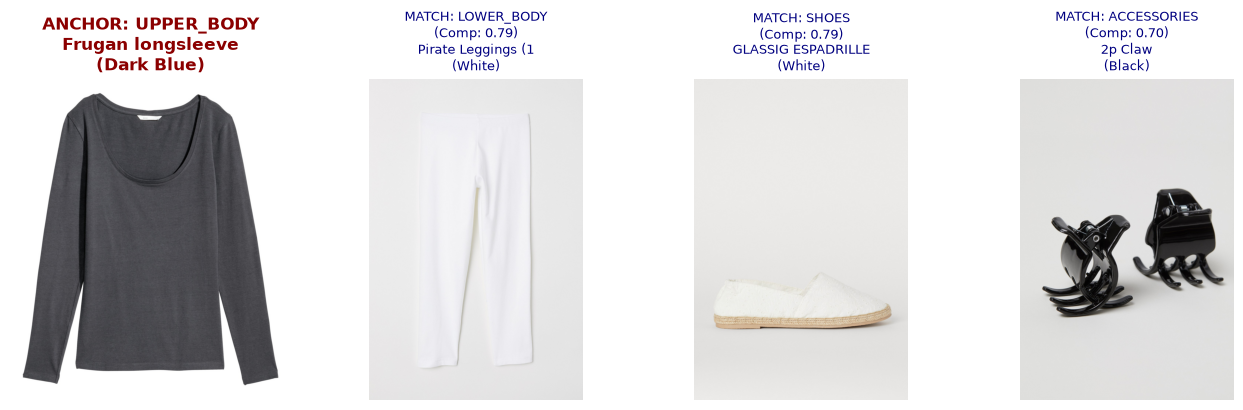

OUTFIT 2: Anchor = Black Lower Body


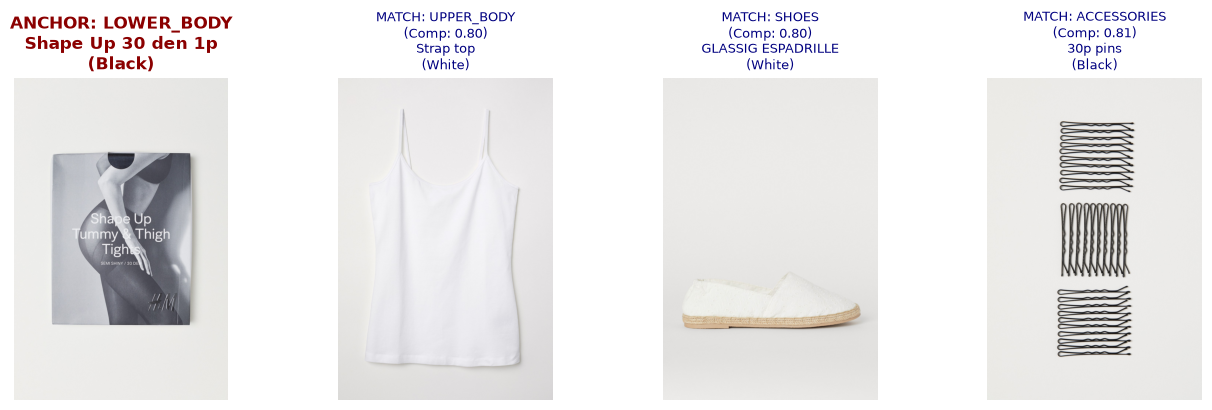

In [5]:
def display_outfit(anchor_id, engine):
    """Generates and visually displays a complete coordinated outfit."""
    outfit = engine.complete_outfit(anchor_id)
    anchor = outfit["anchor"]
    slots = outfit["slots"]
    
    total_slots = 1 + len(slots)
    fig, axes = plt.subplots(1, total_slots, figsize=(3.3 * total_slots, 4.2))
    
    # 1. Plot Anchor
    q_path = PROJECT_ROOT / anchor["image_path"]
    with Image.open(q_path) as img:
        axes[0].imshow(img.convert("RGB"))
    axes[0].set_title(f"ANCHOR: {anchor['slot'].upper()}\n{anchor['prod_name'][:18]}\n({anchor['color']})", color="darkred", fontweight="bold")
    axes[0].axis("off")
    
    # 2. Plot Completed Slots
    for i, (slot_name, item) in enumerate(slots.items(), 1):
        ax = axes[i]
        r_path = PROJECT_ROOT / item["image_path"]
        with Image.open(r_path) as img:
            ax.imshow(img.convert("RGB"))
        ax.set_title(f"MATCH: {slot_name.upper()}\n(Comp: {item['compatibility_score']:.2f})\n{item['prod_name'][:18]}\n({item['color']})", color="navy", fontsize=9)
        ax.axis("off")
        
    plt.tight_layout()
    plt.show()
    return outfit

# Test 1: Anchor on an Upper Body garment
test_upper = df_articles[
    (df_articles["standard_category"] == "upper_body") & 
    (df_articles["has_image"] == 1) &
    (df_articles["colour_group_name"] == "Dark Blue")
]["article_id"].iloc[0]

print("OUTFIT 1: Anchor = Dark Blue Upper Body")
outfit_1 = display_outfit(test_upper, outfit_engine)

# Test 2: Anchor on a Lower Body garment
test_lower = df_articles[
    (df_articles["standard_category"] == "lower_body") & 
    (df_articles["has_image"] == 1) &
    (df_articles["colour_group_name"] == "Black")
]["article_id"].iloc[0]

print("OUTFIT 2: Anchor = Black Lower Body")
outfit_2 = display_outfit(test_lower, outfit_engine)


## Section 5: Outfit Latency & Diversity Benchmark

### What we are doing:
We benchmark the end-to-end latency of complete outfit synthesis across 50 random anchors, ensuring it executes well within the 100ms threshold for real-time frontend responses.


In [6]:
# Benchmark outfit generation speed
np.random.seed(42)
test_anchors = np.random.choice(slot_catalog["upper_body"], size=50, replace=False)

latencies_ms = []
for aid in test_anchors:
    t0 = time.perf_counter()
    res = outfit_engine.complete_outfit(aid)
    latencies_ms.append((time.perf_counter() - t0) * 1000)

lat_series = pd.Series(latencies_ms)
mean_lat = lat_series.mean()
p95_lat = lat_series.quantile(0.95)

print("=" * 60)
print("OUTFIT COMPATIBILITY ENGINE BENCHMARK (50 RUNS):")
print(f"Mean Generation Latency: {mean_lat:.2f} ms")
print(f"p95 Latency:             {p95_lat:.2f} ms")
print(f"Slots Filled:            Upper, Lower, Shoes, Accessories")
print("=" * 60)

# Save outfit config
outfit_config = {
    "engine": "OutfitCompatibilityEngine",
    "slots": ["upper_body", "lower_body", "full_body", "shoes", "accessories"],
    "weights": {"color_harmony": 0.50, "index_group_match": 0.30, "basket_cooccur": 0.20},
    "mean_latency_ms": round(float(mean_lat), 2),
    "p95_latency_ms": round(float(p95_lat), 2)
}

with open(ARTIFACTS_META_DIR / "outfit_engine_config.json", "w", encoding="utf-8") as f:
    json.dump(outfit_config, f, indent=2)

print("Saved outfit configuration to artifacts/metadata/outfit_engine_config.json")


OUTFIT COMPATIBILITY ENGINE BENCHMARK (50 RUNS):
Mean Generation Latency: 0.99 ms
p95 Latency:             1.49 ms
Slots Filled:            Upper, Lower, Shoes, Accessories
Saved outfit configuration to artifacts/metadata/outfit_engine_config.json


## Section 6: Validation Assertions & Stage Sign-Off

### What we are doing:
We run formal assertions verifying that:
1. Completed outfits never duplicate the anchor's slot (e.g. upper body never recommends another upper body item).
2. Every outfit includes valid items with verified image paths.
3. Generation latency p95 is under 100ms.


In [7]:
# Formal Validation Checks
print("Executing Outfit Compatibility Engine Assertions...")

# 1. Slot exclusivity check
anchor_slot_1 = outfit_1["anchor"]["slot"]
for slot_name, item in outfit_1["slots"].items():
    assert item["slot"] != anchor_slot_1, f"Slot collision! Found {item['slot']} inside completed slots for {anchor_slot_1} anchor"
    assert item["image_path"] is not None, "Missing image path in completed outfit slot"

# 2. Score validity
for item in outfit_1["slots"].values():
    assert 0.0 <= item["compatibility_score"] <= 1.0, "Compatibility score out of bounds"

# 3. Latency check
assert p95_lat < 100.0, f"p95 Latency ({p95_lat:.2f} ms) exceeded 100ms threshold!"

print("=" * 60)
print("ALL OUTFIT COMPATIBILITY ASSERTIONS PASSED (100% OK)")
print("Notebook 08 execution complete. Ready for Notebook 09: Model Evaluation.")
print("=" * 60)


Executing Outfit Compatibility Engine Assertions...
ALL OUTFIT COMPATIBILITY ASSERTIONS PASSED (100% OK)
Notebook 08 execution complete. Ready for Notebook 09: Model Evaluation.
